# N-Body Simulation with GPU

N Body simulation shows forces exerted by different bodies on each other because of their gravitational forces.

For this implementation, we have time complexity as $O(N^2)$ but parallelized with GPU

In [1]:
import platform

match platform.system():
    case "Linux":
        !lscpu | grep -E "Model name|^CPU\(s\)"
    case "Darwin":
        !sysctl machdep.cpu.brand_string hw.physicalcpu hw.logicalcpu
    case "Windows":
        !powershell -NoProfile -Command "Get-CimInstance Win32_Processor | Select-Object Name, NumberOfCores, NumberOfLogicalProcessors | Format-Table -AutoSize"
    case other:
        print(f"CPU information command not configured for: {other}")

!nvidia-smi --query-gpu=name,memory.total --format=csv

CPU(s):                                  2
Model name:                              Intel(R) Xeon(R) CPU @ 2.00GHz
name, memory.total [MiB]
Tesla T4, 15360 MiB


In [2]:
from pathlib import Path
import os
import sys
from pprint import pprint

# Change this if your Drive clone is somewhere else.
DRIVE_PROJECT_ROOT = Path("/content/drive/MyDrive/projects/n-body-simulation")
try:
    from google.colab import drive
except ImportError:
    PROJECT_ROOT = Path.cwd().resolve()
    if not (PROJECT_ROOT / "comparison_config.json").is_file():
        PROJECT_ROOT = PROJECT_ROOT.parent
else:
    drive.mount("/content/drive")
    PROJECT_ROOT = DRIVE_PROJECT_ROOT
sys.path.insert(0, str(PROJECT_ROOT))

from benchmark import load_settings, render_animation, run_main, run_scaling, run_experiment

SETTINGS = load_settings(PROJECT_ROOT)
VARIANT = "naive"
VARIANT_FOLDER = PROJECT_ROOT / "gpu_naive"
os.chdir(VARIANT_FOLDER)
print("Output folder:", VARIANT_FOLDER)

POSITIONS_FILE = "positions.csv"
FINAL_STATE_FILE = "final_state.csv"
SCALING_FILE = "scaling.csv"
GIF_FILE = "nbody.gif"
pprint("Shared run settings:")
pprint(SETTINGS)


Mounted at /content/drive
Output folder: /content/drive/MyDrive/projects/n-body-simulation/gpu_naive
'Shared run settings:'
{'barnes_hut': {'check_bodies': 0,
                'max_frame_bodies': 32768,
                'opening_angle': 0.6,
                'resort_every': 4,
                'scenario': 2},
 'benchmark': {'body_counts': [16, 64, 256, 1024, 2048, 4096, 8192, 10000],
               'save_every': 0,
               'steps': 100},
 'gravitational_constant': 0.001,
 'main': {'bodies': 10000, 'save_every': 2, 'steps': 1000},
 'optimised_slices': 0,
 'seed': 42,
 'softening': 0.01,
 'time_step': 0.005}


In [3]:
%%writefile nbody_naive.cu
#include <cstdio>
#include <cstdlib>
#include <cmath>
#include <ctime>
#include <chrono>
#include <utility>
#include <cuda_runtime.h>

#ifndef INITIAL_SEED
#define INITIAL_SEED 42
#endif

// Number of bodies in the simulation
const int NUM_BODIES = 10000;

// Simulation steps
const int NUM_STEPS = 1000;

// Time step for simulation
const float TIME_STEP = 0.005f;

// Save every n steps (0 means do not save)
const int SAVE_EVERY = 2;

// Universal gravitational constant
const float GRAVITATIONAL_CONSTANT = 0.001; // 6.67430e-11f;

// Softening factor to prevent singularities in force calculation
const float SOFTENING = 0.01f;

// CUDA block size for kernel launches
const int BLOCK_SIZE = 256;

double nowMs()
{
    using namespace std::chrono;
    return duration<double, std::milli>(steady_clock::now().time_since_epoch()).count();
}

// Bodies start in a thin ring. The w component stores mass.
void initBodies(float4* position, float3* velocity, int numBodies)
{
    srand(INITIAL_SEED);
    for (int i = 0; i < numBodies; i++)
    {
        float radius = 1.0f + (rand() / (float)RAND_MAX) * 3.0f;
        float angle = (rand() / (float)RAND_MAX) * 2.0f * M_PI;

        position[i].x = radius * cosf(angle);
        position[i].y = radius * sinf(angle);
        position[i].z = ((rand() / (float)RAND_MAX) - 0.5f) * 0.5f;
        position[i].w = 1.0f + (rand() / (float)RAND_MAX) * 5.0f;

        float speed = 0.5f * sqrtf(1.0f / radius);
        velocity[i].x = -speed * sinf(angle);
        velocity[i].y = speed * cosf(angle);
        velocity[i].z = 0.0f;
    }
}

// Add body2's pull to body1's acceleration.
__device__ float3 addForce(
    float4 body1, float4 body2, float3 acceleration, float gravitationalConstant, float softening)
{
    float deltaX = body2.x - body1.x;
    float deltaY = body2.y - body1.y;
    float deltaZ = body2.z - body1.z;

    // Softening keeps the denominator above zero when positions match.
    float distanceSquared = deltaX * deltaX + deltaY * deltaY + deltaZ * deltaZ + softening;
    float inverseDistance = rsqrtf(distanceSquared);
    // The displacement below needs a scale of 1 / distance^3.
    float accelerationScale =
        gravitationalConstant * body2.w * inverseDistance * inverseDistance * inverseDistance;

    acceleration.x += deltaX * accelerationScale;
    acceleration.y += deltaY * accelerationScale;
    acceleration.z += deltaZ * accelerationScale;
    return acceleration;
}

// Each thread handles one body and loops over all source bodies.
// Each thread reads source bodies directly from global memory.
__global__ void updateBodies(const float4* position, float3* velocity, float4* newPosition, int numBodies,
    float timeStep, float gravitationalConstant, float softening)
{
    int i = blockIdx.x * blockDim.x + threadIdx.x;
    // Skip extra threads in the last block.
    if (i >= numBodies)
    {
        return;
    }

    float4 body1 = position[i];
    float3 acceleration = make_float3(0.0f, 0.0f, 0.0f);
    for (int j = 0; j < numBodies; j++)
    {
        acceleration = addForce(body1, position[j], acceleration, gravitationalConstant, softening);
    }

    // Update velocity first, then use it to move the body.
    float3 updatedVelocity = velocity[i];
    updatedVelocity.x += acceleration.x * timeStep;
    updatedVelocity.y += acceleration.y * timeStep;
    updatedVelocity.z += acceleration.z * timeStep;
    velocity[i] = updatedVelocity;

    newPosition[i] = make_float4(body1.x + updatedVelocity.x * timeStep,
        body1.y + updatedVelocity.y * timeStep, body1.z + updatedVelocity.z * timeStep, body1.w);
}

void saveFrame(FILE* file, int step, const float4* position, int numBodies)
{
    for (int i = 0; i < numBodies; i++)
    {
        fprintf(
            file, "%d,%d,%f,%f,%f,%f\n", step, i, position[i].x, position[i].y, position[i].z, position[i].w);
    }
}

void printReport(const char* version, int numBodies, int numSteps, double setupMs, double computeMs,
    double gpuMs, double saveMs, double totalMs, double cpuMs, float timeStep, int saveEvery,
    float gravitationalConstant, float softening)
{
    // About 20 floating point operations per pair of bodies.
    double pairs = (double)numBodies * numBodies * numSteps;
    printf("version              : %s\n", version);
    printf("random seed          : %u\n", (unsigned int)INITIAL_SEED);
    printf("bodies               : %d\n", numBodies);
    printf("steps                : %d\n", numSteps);
    printf("time step            : %.9g\n", timeStep);
    printf("save every           : %d\n", saveEvery);
    printf("gravitational constant: %.9g\n", gravitationalConstant);
    printf("softening            : %.9g\n", softening);
    printf("block size           : %d\n", BLOCK_SIZE);
    printf("setup time ms        : %.3f\n", setupMs);
    printf("compute time ms      : %.3f\n", computeMs);
    printf("gpu time ms          : %.3f\n", gpuMs);
    printf("saving time ms       : %.3f\n", saveMs);
    printf("total time ms        : %.3f\n", totalMs);
    printf("cpu time ms          : %.3f\n", cpuMs);
    printf("ms per step          : %.4f\n", computeMs / numSteps);
    printf("billion pairs per sec: %.3f\n", pairs / (computeMs * 1e6));
    printf("gflops               : %.2f\n", 20.0 * pairs / (computeMs * 1e6));
}

int main(int argc, char** argv)
{
    // ./nbody_naive.out [bodies] [steps] [timeStep] [saveEvery] [gravitationalConstant] [softening]
    int numBodies = (argc > 1) ? atoi(argv[1]) : NUM_BODIES;
    int numSteps = (argc > 2) ? atoi(argv[2]) : NUM_STEPS;
    float timeStep = (argc > 3) ? atof(argv[3]) : TIME_STEP;
    int saveEvery = (argc > 4) ? atoi(argv[4]) : SAVE_EVERY; // 0 means no frames are saved.
    float gravitationalConstant = (argc > 5) ? atof(argv[5]) : GRAVITATIONAL_CONSTANT;
    float softening = (argc > 6) ? atof(argv[6]) : SOFTENING;

    double programStart = nowMs();
    clock_t cpuStart = clock();

    float4* position = new float4[numBodies];
    float3* velocity = new float3[numBodies];
    initBodies(position, velocity, numBodies);

    // Setup time includes starting the GPU on the first CUDA call.
    float4 *gpuPosition, *gpuNewPosition;
    float3* gpuVelocity;
    cudaMalloc(&gpuPosition, numBodies * sizeof(float4));
    cudaMalloc(&gpuNewPosition, numBodies * sizeof(float4));
    cudaMalloc(&gpuVelocity, numBodies * sizeof(float3));
    cudaMemcpy(gpuPosition, position, numBodies * sizeof(float4), cudaMemcpyHostToDevice);
    cudaMemcpy(gpuVelocity, velocity, numBodies * sizeof(float3), cudaMemcpyHostToDevice);

    int numBlocks = (numBodies + BLOCK_SIZE - 1) / BLOCK_SIZE;

    cudaEvent_t start, stop;
    cudaEventCreate(&start);
    cudaEventCreate(&stop);

    FILE* framesFile = fopen(POSITIONS_FILE, "w");
    fprintf(framesFile, "step,id,x,y,z,mass\n");

    double setupMs = nowMs() - programStart;
    double gpuMs = 0.0;
    double saveMs = 0.0;
    if (saveEvery > 0)
    {
        double saveStart = nowMs();
        saveFrame(framesFile, 0, position, numBodies);
        saveMs += nowMs() - saveStart;
    }

    for (int step = 0; step < numSteps; step++)
    {
        // Time the kernel only, without frame copies or file writes.
        cudaEventRecord(start);
        updateBodies<<<numBlocks, BLOCK_SIZE>>>(
            gpuPosition, gpuVelocity, gpuNewPosition, numBodies, timeStep, gravitationalConstant, softening);
        cudaEventRecord(stop);
        cudaEventSynchronize(stop);

        float stepMs = 0.0f;
        cudaEventElapsedTime(&stepMs, start, stop);
        gpuMs += stepMs;
        // Use the new positions as input for the next step.
        std::swap(gpuPosition, gpuNewPosition);

        // Copy positions back to the CPU before saving a frame.
        if (saveEvery > 0 && (step + 1) % saveEvery == 0)
        {
            double saveStart = nowMs();
            cudaMemcpy(position, gpuPosition, numBodies * sizeof(float4), cudaMemcpyDeviceToHost);
            saveFrame(framesFile, step + 1, position, numBodies);
            saveMs += nowMs() - saveStart;
        }
    }
    fclose(framesFile);

    cudaError_t err = cudaGetLastError();
    if (err != cudaSuccess)
    {
        printf("CUDA error: %s\n", cudaGetErrorString(err));
        return 1;
    }

    cudaMemcpy(position, gpuPosition, numBodies * sizeof(float4), cudaMemcpyDeviceToHost);
    cudaMemcpy(velocity, gpuVelocity, numBodies * sizeof(float3), cudaMemcpyDeviceToHost);

    FILE* finalFile = fopen(FINAL_STATE_FILE, "w");
    fprintf(finalFile, "id,x,y,z,vx,vy,vz,mass\n");
    for (int i = 0; i < numBodies; i++)
    {
        fprintf(finalFile, "%d,%f,%f,%f,%f,%f,%f,%f\n", i, position[i].x, position[i].y, position[i].z,
            velocity[i].x, velocity[i].y, velocity[i].z, position[i].w);
    }
    fclose(finalFile);

    cudaFree(gpuPosition);
    cudaFree(gpuNewPosition);
    cudaFree(gpuVelocity);
    delete[] position;
    delete[] velocity;

    double totalMs = nowMs() - programStart;
    double cpuMs = 1000.0 * (clock() - cpuStart) / CLOCKS_PER_SEC;
    printReport("v2 naive GPU", numBodies, numSteps, setupMs, gpuMs, gpuMs, saveMs, totalMs, cpuMs, timeStep,
        saveEvery, gravitationalConstant, softening);
    return 0;
}

Writing nbody_naive.cu


In [4]:
!time nvcc -O3 -arch=sm_75 -DINITIAL_SEED={SETTINGS["seed"]} -o nbody_naive.out nbody_naive.cu '-DPOSITIONS_FILE="{POSITIONS_FILE}"' '-DFINAL_STATE_FILE="{FINAL_STATE_FILE}"'


real	0m3.279s
user	0m1.615s
sys	0m0.377s


In [5]:
# The shared settings keep the physical inputs and saved steps aligned.
import pandas as pd

main_run = run_main(VARIANT, SETTINGS)
display(pd.DataFrame([main_run["metrics"]]))


Saved gpu_naive/run.json for 10,000 bodies and 1,000 steps.


,random seed,bodies,steps,time step,save every,gravitational constant,softening,block size,setup time ms,compute time ms,gpu time ms,saving time ms,cpu time ms,ms per step,billion pairs per sec,gflops,total ms
0,42,10000,1000,0.005,2,0.001,0.01,256,319.767,1742.526,1742.526,8652.376,8077.144,1.742526,57.388,1147.76,10760.885


## Final state

In [6]:
import pandas as pd

final_state = pd.read_csv(FINAL_STATE_FILE)
final_state.head()

,id,x,y,z,vx,vy,vz,mass
0,0,-3.321456,-0.235307,-0.028915,-0.553028,-1.506632,-1.072747,3.112433
1,1,-1.979533,-0.305273,-0.065802,-1.554188,-1.560102,-0.439423,5.318112
2,2,-1.468123,-0.312391,-0.009733,-1.393827,0.142578,-0.531470,4.826905
3,3,-1.236967,-0.215938,0.123486,-2.582216,-3.739449,2.196459,4.803358
4,4,-1.359257,1.510219,-0.266899,-1.667109,-2.053394,-0.220154,4.716352


## Animation
The saved frames use the same x-y view and playback rate across all variants.


In [7]:
from IPython.display import Image

animation_path = render_animation(VARIANT, SETTINGS, GIF_FILE)
display(Image(filename=str(animation_path)))


Output hidden; open in https://colab.research.google.com to view.

In [8]:
try:
    from google.colab import files
    files.download(GIF_FILE)
except ImportError:
    print("not running in Colab, the GIF is in the working folder")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## How the time grows with N

In [9]:
import pandas as pd

# Each benchmark runs separately so the main frames and final state stay unchanged.
dataframe = pd.DataFrame(run_scaling(VARIANT, SETTINGS))
display(dataframe)


Running Naive CUDA with 16 bodies
Running Naive CUDA with 64 bodies
Running Naive CUDA with 256 bodies
Running Naive CUDA with 1,024 bodies
Running Naive CUDA with 2,048 bodies
Running Naive CUDA with 4,096 bodies
Running Naive CUDA with 8,192 bodies
Running Naive CUDA with 10,000 bodies


,version,random seed,bodies,steps,time step,save every,gravitational constant,softening,block size,setup time ms,compute time ms,gpu time ms,saving time ms,cpu time ms,ms per step,billion pairs per sec,gflops,total ms
0,Naive CUDA,42,16,100,0.005,0,0.001,0.01,256,317.529,1.151,1.151,0.0,300.218,0.01151,0.022,0.44,319.971
1,Naive CUDA,42,64,100,0.005,0,0.001,0.01,256,222.782,1.131,1.131,0.0,213.098,0.01131,0.362,7.24,225.204
2,Naive CUDA,42,256,100,0.005,0,0.001,0.01,256,200.472,2.270,2.270,0.0,178.682,0.02270,2.887,57.74,204.470
3,Naive CUDA,42,1024,100,0.005,0,0.001,0.01,256,204.805,9.575,9.575,0.0,193.572,0.09575,10.951,219.03,222.543
4,Naive CUDA,42,2048,100,0.005,0,0.001,0.01,256,207.977,19.367,19.367,0.0,214.712,0.19367,21.657,433.13,235.603
5,Naive CUDA,42,4096,100,0.005,0,0.001,0.01,256,172.838,37.654,37.654,0.0,218.008,0.37654,44.556,891.12,218.903
6,Naive CUDA,42,8192,100,0.005,0,0.001,0.01,256,177.017,69.811,69.811,0.0,250.253,0.69811,96.130,1922.59,258.848
7,Naive CUDA,42,10000,100,0.005,0,0.001,0.01,256,168.740,82.400,82.400,0.0,265.209,0.82400,121.359,2427.18,266.532


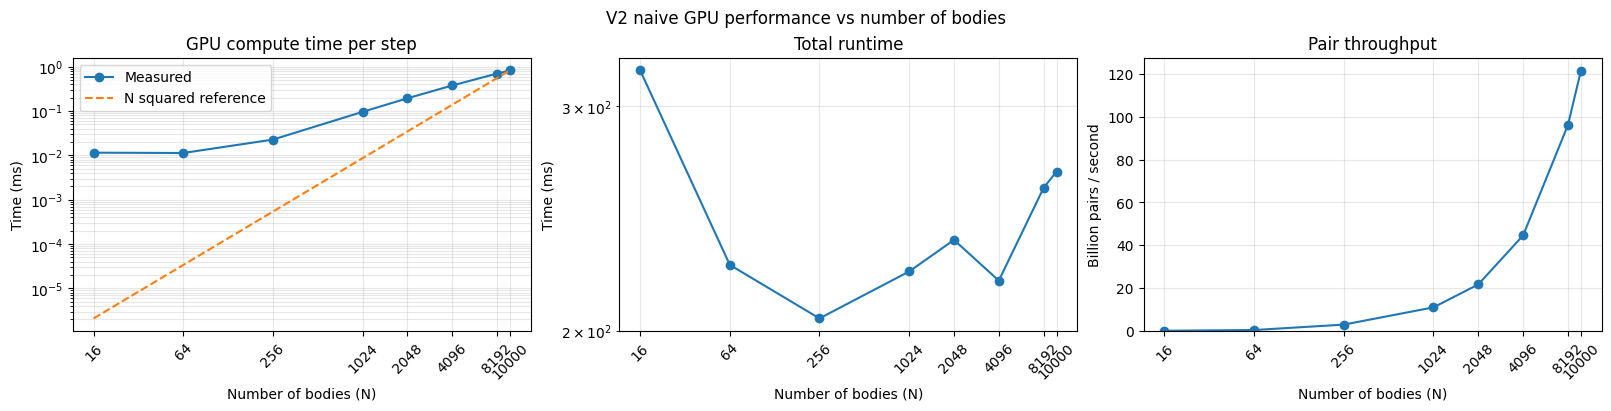

In [10]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(16, 4), constrained_layout=True)
plots = [
    ("ms per step", "GPU compute time per step", "Time (ms)"),
    ("total ms", "Total runtime", "Time (ms)"),
    ("billion pairs per sec", "Pair throughput", "Billion pairs / second"),
]

for ax, (metric, title, ylabel) in zip(axes, plots):
    ax.plot(dataframe["bodies"], dataframe[metric], marker="o", label="Measured")
    ax.set_xscale("log", base=2)
    ax.set_xticks(dataframe["bodies"], labels=dataframe["bodies"].astype(str))
    ax.tick_params(axis="x", labelrotation=45)
    ax.set_xlabel("Number of bodies (N)")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.grid(True, which="both", alpha=0.3)

for ax in axes[:2]:
    ax.set_yscale("log")

reference = dataframe["ms per step"].iloc[-1] * (
    dataframe["bodies"] / dataframe["bodies"].iloc[-1]
) ** 2
axes[0].plot(dataframe["bodies"], reference, "--", label="N squared reference")
axes[0].legend()
axes[2].set_ylim(bottom=0)
fig.suptitle("V2 naive GPU performance vs number of bodies")
plt.show()